In [1]:
import os
import cv2
import torch
import pandas as pd
import torch.nn as nn
import random
import itertools
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR
from torch.optim import AdamW

from sklearn.metrics import accuracy_score

In [2]:
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [3]:
device = torch.device("cuda:3" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:3


In [4]:
class ImageDataset(Dataset):
    def __init__(self, folder, csv_path, size=(224, 224), mean=None, std=None):
        df = pd.read_csv(csv_path, usecols=["filename", "category_id"])
        self.files = df["filename"].astype(str).tolist()
        self.labels = df["category_id"].astype(int).tolist()
        self.folder = folder
        self.size = size
        self.normalize = mean is not None and std is not None

        if self.normalize:
            self.mean = torch.as_tensor(mean, dtype=torch.float32).view(3, 1, 1)
            self.std = torch.as_tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = os.path.join(self.folder, self.files[idx])
        img = cv2.imread(path)
        if img is None:
            raise ValueError(f"Could not read image: {path}")

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, self.size, interpolation=cv2.INTER_AREA)

        img = torch.from_numpy(img).permute(2, 0, 1).float().div_(255.0)

        if self.normalize:
            img = (img - self.mean) / self.std

        return img, self.labels[idx]

In [5]:
@torch.no_grad()
def compute_mean_std(dataset, batch_size=64, num_workers=4):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    n_pixels = 0
    ch_sum = torch.zeros(3, dtype=torch.float64)
    ch_sqsum = torch.zeros(3, dtype=torch.float64)

    for x, _ in loader:
        x = x.double()
        n_pixels += x.shape[0] * x.shape[2] * x.shape[3]
        ch_sum += x.sum(dim=(0, 2, 3))
        ch_sqsum += (x ** 2).sum(dim=(0, 2, 3))

    mean = ch_sum / n_pixels
    std = (ch_sqsum / n_pixels - mean ** 2).sqrt()
    return mean.float().tolist(), std.float().tolist()

In [6]:
raw_train = ImageDataset("dataset_updated/224x224", "dataset_updated/train/listings_train.csv")
mean, std = compute_mean_std(raw_train)
print(mean, std)

[0.5493555665016174, 0.5115177631378174, 0.47487103939056396] [0.33919447660446167, 0.3244801461696625, 0.32308244705200195]


In [7]:
train_ds = ImageDataset("dataset_updated/224x224", "dataset_updated/train/listings_train.csv", mean=mean, std=std)
val_ds = ImageDataset("dataset_updated/224x224", "dataset_updated/validation/listings_val.csv", mean=mean, std=std)
test_ds = ImageDataset("dataset_updated/224x224", "dataset_updated/test/listings_test.csv", mean=mean, std=std)

In [8]:
print(f"train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

train 45593 | val 5700 | test 5700


In [9]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=4, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=4)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True, prefetch_factor=4)

Basis:
https://www.mdpi.com/2226-4310/13/10/864#Network_Model_a4

In [10]:
class CoordAtt(nn.Module):
    def __init__(self, channels, reduction=32):
        super().__init__()

        mid = max(8, channels // reduction)

        self.conv1 = nn.Conv2d(channels, mid, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid)
        self.act = nn.Hardswish()

        self.conv_h = nn.Conv2d(mid, channels, kernel_size=1)
        self.conv_w = nn.Conv2d(mid, channels, kernel_size=1)

    def forward(self, x):
        _, _, h, w = x.shape

        x_h = x.mean(dim=3, keepdim=True)

        x_w = x.mean(dim=2, keepdim=True).permute(0, 1, 3, 2)

        y = torch.cat([x_h, x_w], dim=2)

        y = self.act(self.bn1(self.conv1(y)))
        y_h, y_w = torch.split(y, [h, w], dim=2)

        y_w = y_w.permute(0, 1, 3, 2)

        a_h = torch.sigmoid(self.conv_h(y_h))
        a_w = torch.sigmoid(self.conv_w(y_w))

        return x * a_h * a_w

In [11]:
class Bottleneck(nn.Module):
    expansion = 4
    
    def __init__(self, in_channels, channels, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, channels, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)
        self.conv3 = nn.Conv2d(channels, channels * self.expansion, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(channels * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return self.relu(out + identity)

In [12]:
class ResNetCA(nn.Module):
    def __init__(self, in_channels=3, num_classes=30, layers=(3, 4, 6, 3), dropout=0.3):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv2d(in_channels, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, 2, 1)

        self.layer1 = self._make_layer(64,  layers[0], stride=1)   # -> 256
        self.layer2 = self._make_layer(128, layers[1], stride=2)   # -> 512
        self.layer3 = self._make_layer(256, layers[2], stride=2)   # -> 1024
        self.layer4 = self._make_layer(512, layers[3], stride=2)   # -> 2048

        self.att1 = CoordAtt(512)    # after layer2 (128 * 4)
        self.att2 = CoordAtt(2048)   # after layer4 (512 * 4)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(2048, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )
        self._initialize_weights()

In [13]:
def make_layer(self, channels, blocks, stride):
    out_channels = channels * Bottleneck.expansion
    downsample = None
    if stride != 1 or self.in_channels != out_channels:
        downsample = nn.Sequential(
            nn.Conv2d(self.in_channels, out_channels, 1, stride, bias=False),
            nn.BatchNorm2d(out_channels),
        )
    layers = [Bottleneck(self.in_channels, channels, stride, downsample)]
    self.in_channels = out_channels
    layers += [Bottleneck(self.in_channels, channels) for _ in range(1, blocks)]
    return nn.Sequential(*layers)

ResNetCA._make_layer = make_layer

In [14]:
def forward(self, x):
    x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
    x = self.layer1(x)
    x = self.att1(self.layer2(x))
    x = self.layer3(x)
    x = self.att2(self.layer4(x))
    x = torch.flatten(self.gap(x), 1)
    return self.fc(x)

ResNetCA.forward = forward

In [15]:
def initialize_weights(self):
    for m in self.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.constant_(m.weight, 1); nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0, 0.01); nn.init.constant_(m.bias, 0)
            
ResNetCA._initialize_weights = initialize_weights

In [16]:
def build_model():
    
    model = ResNetCA(in_channels=3, num_classes=30).to(device)
    for m in model.modules():
        if isinstance(m, Bottleneck):
            nn.init.constant_(m.bn3.weight, 0)
            
    return model

In [17]:
def build_optimizer(model, lr, wd):
    
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    
    return torch.optim.AdamW([{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}], lr=lr)

In [18]:
def build_scheduler(optimizer, epochs, warmup):
    s1 = LinearLR(optimizer, start_factor=0.1, total_iters=warmup)
    s2 = CosineAnnealingLR(optimizer, T_max=epochs - warmup)
    return SequentialLR(optimizer, [s1, s2], milestones=[warmup])

In [19]:
class Tracker:
    def __init__(self, patience, save_prefix=None):
        self.patience, self.save_prefix = patience, save_prefix
        self.best_acc, self.best_loss, self.bad = 0.0, float("inf"), 0

    def _save(self, model, suffix):
        if self.save_prefix:
            torch.save(model.state_dict(), f"{self.save_prefix}_{suffix}.pth")

    def update(self, model, val_loss, val_acc):
        if val_acc > self.best_acc:
            self.best_acc = val_acc
            self._save(model, "acc")
        if val_loss < self.best_loss:
            self.best_loss, self.bad = val_loss, 0
            self._save(model, "loss")
        else:
            self.bad += 1
        return self.bad >= self.patience

In [20]:
def log_epoch(epoch, epochs, lr, train_res, val_res):
    tl, ta = train_res
    vl, va, v3, v5 = val_res
    print(f"Epoch [{epoch+1}/{epochs}] LR: {lr:.2e}")
    print(f"Train Loss: {tl:.4f} | Train Acc: {ta:.4f}")
    print(f"Val Loss: {vl:.4f} | Val Acc: {va:.4f} | Top-3: {v3:.4f} | Top-5: {v5:.4f}")

In [21]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

In [22]:
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, top3, top5, total = 0.0, 0, 0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            topk = outputs.topk(5, dim=1).indices
            hits = topk == labels.unsqueeze(1)

            total_loss += loss.item() * labels.size(0)
            correct += hits[:, :1].any(1).sum().item()
            top3    += hits[:, :3].any(1).sum().item()
            top5    += hits.any(1).sum().item()
            total   += labels.size(0)

    return total_loss / total, correct / total, top3 / total, top5 / total

In [23]:
def fit(lr=1e-3, wd=5e-2, label_smoothing=0.1, epochs=30, warmup=2, patience=8, verbose=True, save_prefix=None, seed=42):
    torch.manual_seed(seed)
    model = build_model()
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = build_optimizer(model, lr, wd)
    scheduler = build_scheduler(optimizer, epochs, warmup)
    tracker = Tracker(patience, save_prefix)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        tr = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va = evaluate(model, val_loader, criterion, device)
        history["train_loss"].append(tr[0]); history["train_acc"].append(tr[1])
        history["val_loss"].append(va[0]);   history["val_acc"].append(va[1])

        lr_now = optimizer.param_groups[0]["lr"]
        scheduler.step()
        stop = tracker.update(model, va[0], va[1])

        if verbose:
            log_epoch(epoch, epochs, lr_now, tr, va)
        if stop:
            if verbose:
                print(f"Early stopping at epoch {epoch+1}.")
            break

    return {"model": model, "history": history,
            "best_val_acc": tracker.best_acc, "best_val_loss": tracker.best_loss}

In [24]:
out = fit(lr=1e-3, wd=5e-2, label_smoothing=0.1, epochs=30, warmup=2, patience=8, verbose=True, save_prefix="resnetca_initial")
model = out["model"]
history = out["history"]

Epoch [1/30] LR: 1.00e-04
Train Loss: 3.3102 | Train Acc: 0.0773
Val Loss: 3.2181 | Val Acc: 0.1021 | Top-3: 0.2428 | Top-5: 0.3646
Epoch [2/30] LR: 5.50e-04
Train Loss: 3.2204 | Train Acc: 0.1054
Val Loss: 3.1602 | Val Acc: 0.1239 | Top-3: 0.2856 | Top-5: 0.4125
Epoch [3/30] LR: 1.00e-03
Train Loss: 3.1314 | Train Acc: 0.1377
Val Loss: 3.0611 | Val Acc: 0.1602 | Top-3: 0.3254 | Top-5: 0.4584
Epoch [4/30] LR: 9.97e-04
Train Loss: 3.0380 | Train Acc: 0.1702
Val Loss: 3.0262 | Val Acc: 0.1744 | Top-3: 0.3530 | Top-5: 0.4786
Epoch [5/30] LR: 9.87e-04
Train Loss: 2.9692 | Train Acc: 0.1953
Val Loss: 3.0131 | Val Acc: 0.1819 | Top-3: 0.3661 | Top-5: 0.4904
Epoch [6/30] LR: 9.72e-04
Train Loss: 2.9159 | Train Acc: 0.2145
Val Loss: 2.9096 | Val Acc: 0.2147 | Top-3: 0.4033 | Top-5: 0.5284
Epoch [7/30] LR: 9.50e-04
Train Loss: 2.8631 | Train Acc: 0.2279
Val Loss: 2.8855 | Val Acc: 0.2188 | Top-3: 0.4116 | Top-5: 0.5402
Epoch [8/30] LR: 9.23e-04
Train Loss: 2.8139 | Train Acc: 0.2464
Val Loss: 2

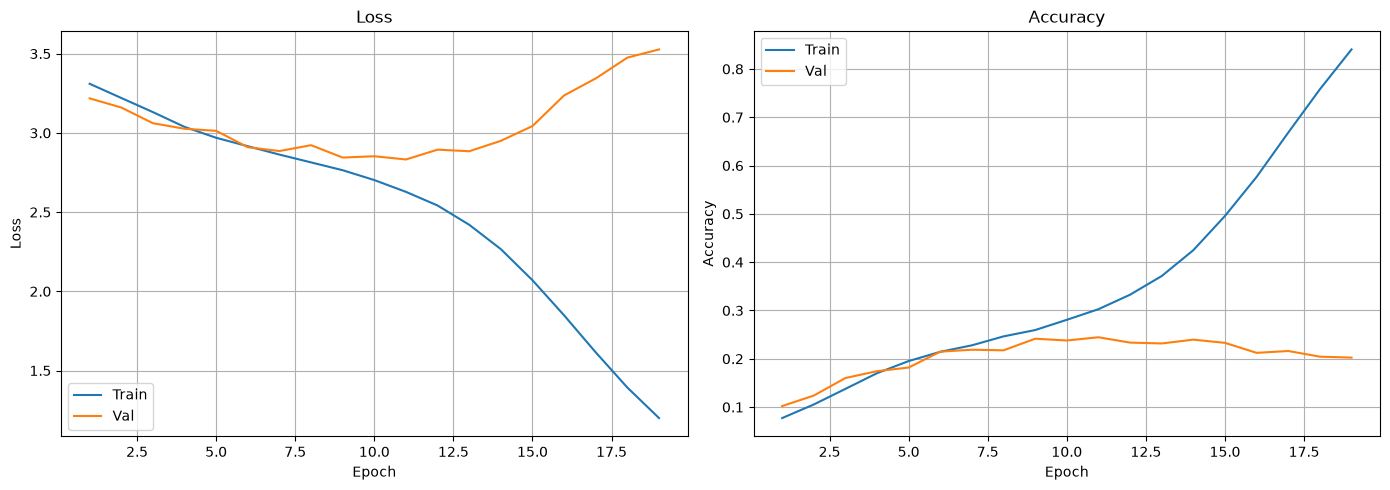

In [25]:
history = out["history"]
train_losses = history["train_loss"]
val_losses = history["val_loss"]
train_accs = history["train_acc"]
val_accs = history["val_acc"]

epochs = range(1, len(train_losses) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epochs, train_losses, label="Train")
ax[0].plot(epochs, val_losses, label="Val")
ax[0].set(xlabel="Epoch", ylabel="Loss", title="Loss")

ax[1].plot(epochs, train_accs, label="Train")
ax[1].plot(epochs, val_accs, label="Val")
ax[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")

for a in ax:
    a.legend()
    a.grid(True)
plt.tight_layout()
plt.show()

## Hyperparameter Tuning

Basis: https://www.sciencedirect.com/science/article/pii/S2772662224000742#sec5

Selected only learning rate and weigh decay

In [ ]:
param_grid = {"lr": [5e-4, 1e-3, 2e-3], "wd": [1e-2, 5e-2]}
results = []

In [ ]:
for values in itertools.product(*param_grid.values()):
    params = dict(zip(param_grid, values))
    t0 = time.time()
    out = fit(**params, epochs=12, patience=4, verbose=False)
    results.append({**params, "val_acc": out["best_val_acc"],
                    "val_loss": out["best_val_loss"]})
    print(f"{params} -> acc {out['best_val_acc']:.4f} | "
          f"loss {out['best_val_loss']:.4f} | {time.time()-t0:.0f}s")
    del out
    torch.cuda.empty_cache()

best = max(results, key=lambda r: r["val_acc"])
print("Best:", best)

In [ ]:
out = fit(lr=best["lr"], wd=best["wd"], epochs=30, patience=8, verbose=True, save_prefix="resnetca_final")
model = out["model"]

model.load_state_dict(torch.load("resnetca_final_loss.pth"))
test_loss, test_acc, test_top3, test_top5 = evaluate(model, test_loader, nn.CrossEntropyLoss(), device)
print(f"Test Acc: {test_acc:.4f} | Top-3: {test_top3:.4f} | Top-5: {test_top5:.4f}")

In [ ]:
history = out["history"]
train_losses, val_losses = history["train_loss"], history["val_loss"]
train_accs, val_accs = history["train_acc"], history["val_acc"]
epochs = range(1, len(train_losses) + 1)

best_ep = val_losses.index(min(val_losses)) + 1   # epoch of the saved "loss" checkpoint

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(epochs, train_losses, label="Train")
ax[0].plot(epochs, val_losses, label="Val")
ax[0].set(xlabel="Epoch", ylabel="Loss", title="Training and Validation Loss")

ax[1].plot(epochs, train_accs, label="Train")
ax[1].plot(epochs, val_accs, label="Val")
ax[1].set(xlabel="Epoch", ylabel="Accuracy", title="Training and Validation Accuracy")

for a in ax:
    a.axvline(best_ep, color="gray", linestyle="--", label=f"Best val loss (epoch {best_ep})")
    a.legend()
    a.grid(True)

plt.tight_layout()
plt.show()